# 05 — HMM and Viterbi route reconstruction

The classifier scores each candidate arc of each GPS point independently, so consecutive points can be
assigned to arcs that are not connected in the road network. An HMM adds the sequence: it prefers
assignments whose movement along the network matches the movement of the GPS.

Code: `pathsnap/hmm/graph.py` (road graph, bounded Dijkstra), `pathsnap/hmm/viterbi.py` (model + decoder),
`pathsnap/hmm/run.py` (tuning + evaluation, `python -m pathsnap.hmm.run`), `pathsnap/pipeline.py` (inference used by the API).

## 1. Model

| Element | Implementation |
|---|---|
| Time steps | GPS observations of one track segment (segments split at gaps > 30 s); GPS outliers are left out and filled afterwards |
| Hidden states | the candidate arcs of the observation (≤ 12), each with its arc id and projection position |
| Emission | `w · log(p_s / Σ p)`: the classifier probability, normalised over the observation's candidates |
| Transition | `−min(\|d_route − d_gps\|, M) / β`: driving distance through the network between the two candidate positions vs straight-line GPS distance (Newson & Krumm, 2009) |
| Route distance | same arc: distance along it; otherwise rest of the first arc + shortest path (bounded Dijkstra) + start of the second |
| No path within reach | mismatch capped at M = 300 m: strongly penalised, never probability 0, so decoding never stops |
| Large GPS gaps | > 30 s: a new HMM chain starts (the vehicle may be anywhere); shorter gaps widen the Dijkstra search with the GPS distance |
| Missing candidates | observations without candidates are not states; outliers take the decoded arc of the nearest decoded observation |
| Decoding | Viterbi in log space: `δ_i(s) = e_i(s) + max_s' [δ_{i−1}(s') + t_i(s', s)]`, back-pointers, then backtracking |
| Route output | decoded arcs per observation, plus a connected route with the gaps filled by shortest paths |

Decoder parameters β and w are chosen on **train only**, using out-of-fold classifier probabilities
(each train trip scored by a model that never saw it).

In [1]:
# --- setup ---
import sys, pathlib
ROOT = pathlib.Path.cwd().resolve()
while not (ROOT / "pathsnap" / "config.py").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathsnap.config import RESULTS_DIR, ARTIFACTS_DIR
H = RESULTS_DIR / "hmm"
if not (H / "summary.csv").exists():
    raise RuntimeError("Run first: python -m pathsnap.hmm.run")
pd.set_option("display.width", 180); pd.set_option("display.max_columns", 30)
plt.rcParams["figure.dpi"] = 110
print("HMM config:", json.loads((ARTIFACTS_DIR / "hmm_config.json").read_text()))

HMM config: {'beta': 40.0, 'emission_weight': 2.0, 'max_mismatch_m': 300.0, 'chosen_by': 'train out-of-fold top-1 grid search', 'grid': {'beta': [2, 5, 10, 20, 40, 80, 160], 'emission_weight': [0.5, 1.0, 2.0]}}


## 2. Tuning on train (out-of-fold probabilities)

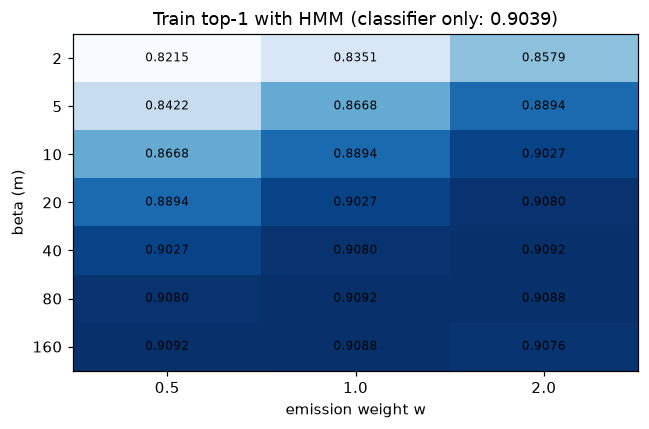

,beta,emission_weight,top1_classifier,top1_hmm,n_points
16,80,1.0,0.90391,0.909232,185076
18,160,0.5,0.90391,0.909232,185076
14,40,2.0,0.90391,0.909232,185076
17,80,2.0,0.90391,0.908843,185076
19,160,1.0,0.90391,0.908843,185076


In [2]:
grid = pd.read_csv(H / "tuning_grid.csv")
piv = grid.pivot(index="beta", columns="emission_weight", values="top1_hmm")
fig, ax = plt.subplots(figsize=(6, 4))
im = ax.imshow(piv, cmap="Blues", aspect="auto")
ax.set_xticks(range(len(piv.columns)), piv.columns); ax.set_yticks(range(len(piv.index)), piv.index)
for i in range(piv.shape[0]):
    for j in range(piv.shape[1]):
        ax.text(j, i, f"{piv.iloc[i, j]:.4f}", ha="center", va="center", fontsize=8)
ax.set_xlabel("emission weight w"); ax.set_ylabel("beta (m)")
ax.set_title(f"Train top-1 with HMM (classifier only: {grid.top1_classifier.iloc[0]:.4f})")
plt.tight_layout(); plt.show()
grid.sort_values("top1_hmm", ascending=False).head(5)

## 3. Classifier-only vs classifier + HMM (student test)

In [3]:
s = pd.read_csv(H / "summary.csv", index_col=0)["value"]
rows = [("Top-1 accuracy (per GPS point)", "top1_classifier", "top1_hmm"),
        ("Route continuity (consecutive arcs connected)", "continuity_cls", "continuity_hmm"),
        ("Route precision (arcs)", "route_precision_cls", "route_precision_hmm"),
        ("Route recall (arcs)", "route_recall_cls", "route_recall_hmm"),
        ("Route F1 (arcs)", "route_f1_cls", "route_f1_hmm"),
        ("Route breaks (no path between consecutive arcs)", "route_breaks_cls", "route_breaks_hmm")]
cmp = pd.DataFrame([(n, float(s[a]), float(s[b])) for n, a, b in rows],
                   columns=["metric", "classifier only", "classifier + HMM"])
cmp["change"] = cmp["classifier + HMM"] - cmp["classifier only"]
cmp.round(4)

,metric,classifier only,classifier + HMM,change
0,Top-1 accuracy (per GPS point),0.9086,0.9152,0.0066
1,Route continuity (consecutive arcs connected),0.9589,0.9764,0.0175
2,Route precision (arcs),0.7609,0.8829,0.1219
3,Route recall (arcs),0.9943,0.9937,-0.0006
4,Route F1 (arcs),0.8574,0.9332,0.0758
5,Route breaks (no path between consecutive arcs),73.0000,17.0000,-56.0000


Point metrics are weighted by each trip's number of reliably labelled points. Route precision/recall compare the set of arcs in the reconstructed route with the reference route.

## 4. Per trip: where the HMM helps and where it does not

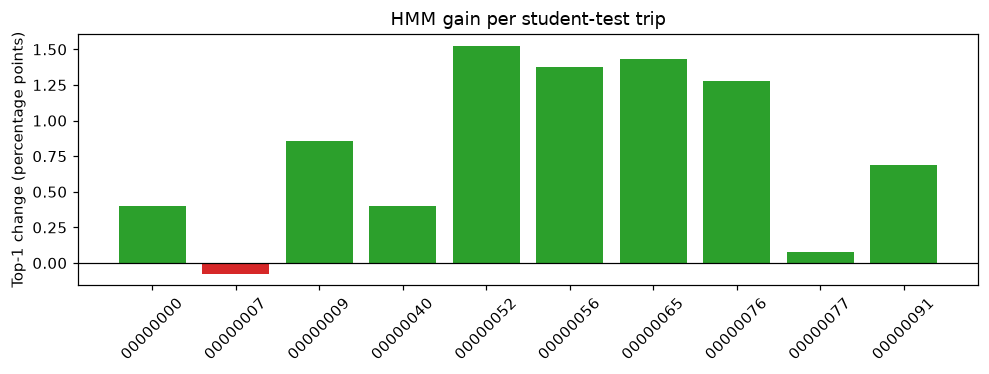

,trip_id,n_points,top1_classifier,top1_hmm,gain,continuity_cls,continuity_hmm,route_f1_cls,route_f1_hmm,route_breaks_hmm,steps_without_any_path
0,00000000,2503,0.9596,0.9636,0.0040,0.9836,0.9936,0.8230,0.9063,2,0
1,00000007,1354,0.9911,0.9904,-0.0007,0.9985,0.9993,0.9758,0.9798,0,0
2,00000009,1049,0.8885,0.8970,0.0086,0.9284,0.9408,0.8910,0.9330,0,0
3,00000040,2995,0.9399,0.9439,0.0040,0.9816,0.9930,0.8729,0.9872,0,0
4,00000052,262,0.9695,0.9847,0.0153,0.9502,0.9617,0.9073,0.9519,1,0
5,00000056,3931,0.9298,0.9435,0.0137,0.9315,0.9580,0.8909,0.9600,13,0
6,00000065,768,0.9232,0.9375,0.0143,0.9700,0.9804,0.6988,0.8555,0,0
7,00000076,1486,0.9341,0.9468,0.0128,0.9340,0.9582,0.7422,0.8486,1,0
8,00000077,3911,0.7949,0.7957,0.0008,0.9634,0.9854,0.8948,0.9178,0,0
9,00000091,874,0.8902,0.8970,0.0069,0.9233,0.9519,0.6824,0.9091,0,0


In [4]:
bt = pd.read_csv(H / "student_test_by_trip.csv", dtype={"trip_id": str})
bt["gain"] = bt.top1_hmm - bt.top1_classifier
fig, ax = plt.subplots(figsize=(9, 3.5))
colors = ["#2ca02c" if g > 0 else "#d62728" for g in bt.gain]
ax.bar(bt.trip_id, 100 * bt.gain, color=colors)
ax.axhline(0, color="black", lw=0.8)
ax.set_ylabel("Top-1 change (percentage points)"); ax.set_title("HMM gain per student-test trip")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()
bt[["trip_id", "n_points", "top1_classifier", "top1_hmm", "gain", "continuity_cls", "continuity_hmm",
    "route_f1_cls", "route_f1_hmm", "route_breaks_hmm", "steps_without_any_path"]].round(4)

## 5. Which errors the HMM removes

In [5]:
from pathsnap.data_processing.loader import load_arcs, trip_dir
pred = pd.read_parquet(H / "predictions_student_test.parquet").dropna(subset=["label_arc"])
pred["label_arc"] = pred["label_arc"].astype(int)
def categorise(df, col):
    out = []
    for tid, g in df.groupby("trip_id"):
        a = load_arcs(trip_dir(tid, "student_test"), tid); u, v = a.u.to_numpy(), a.v.to_numpy()
        p, t = g[col].to_numpy(), g["label_arc"].to_numpy()
        out.append(pd.Series(np.select([p == t, (u[p] == v[t]) & (v[p] == u[t]),
                                        (u[p] == v[t]) | (v[p] == u[t]), (u[p] == u[t]) | (v[p] == v[t])],
                                       ["correct", "reverse twin", "next/previous arc", "sibling at junction"],
                                       "other road")))
    return pd.concat(out).value_counts(normalize=True).mul(100)
pd.DataFrame({"classifier only %": categorise(pred, "cls_arc"), "classifier + HMM %": categorise(pred, "hmm_arc")}).round(2)

,classifier only %,classifier + HMM %
correct,90.86,91.52
reverse twin,3.85,4.09
next/previous arc,1.92,1.81
sibling at junction,1.74,1.34
other road,1.63,1.23


## 6. Map: reference vs classifier-only vs HMM route

In [6]:
from pathsnap.data_processing.loader import load_trip
from pathsnap.hmm.graph import RoadGraph
from pathsnap.hmm.viterbi import reconstruct_route
from pathsnap.viz.maps import trip_map
MAP_TRIP = bt.sort_values("gain", ascending=False).trip_id.iloc[0]      # trip with the largest HMM gain
trip = load_trip(MAP_TRIP, "student_test")
g = RoadGraph(trip.nodes, trip.arcs)
p = pred[pred.trip_id == MAP_TRIP].sort_values("pt")
allp = pd.read_parquet(H / "predictions_student_test.parquet").query("trip_id == @MAP_TRIP").sort_values("pt")
cls_route, _ = reconstruct_route(allp.cls_arc.tolist(), g)
hmm_route, _ = reconstruct_route(allp.hmm_arc.tolist(), g)
m = trip_map(trip, predicted_arcs={"Classifier-only route": cls_route, "HMM route": hmm_route},
             title=f"student_test / {MAP_TRIP}: reference vs classifier vs HMM")
m.save(str(RESULTS_DIR / "maps" / f"hmm_student_test_{MAP_TRIP}.html"))
m

## 7. End-to-end inference (what the API runs) and its latency

In [7]:
from pathsnap.pipeline import Matcher, score_trip
matcher = Matcher()
res = matcher.match("00000000", "student_test")
print("timings (s):", {k: round(v, 3) for k, v in res.timings_s.items()}, "| total", round(sum(res.timings_s.values()), 2))
print("route arcs:", len(res.route_arcs), "| breaks:", res.route_breaks)
score_trip("00000000", "student_test", res)    # server-side scoring against the reference

timings (s): {'load_clean': 0.02, 'candidates_classifier': 0.095, 'hmm_viterbi': 0.563} | total 0.68
route arcs: 242 | breaks: 2


{'n_scored_points': 2503,
 'top1_accuracy_hmm': 0.9636436276468238,
 'top1_accuracy_classifier': 0.9596484218937276,
 'route_precision': 0.8287037037037037,
 'route_recall': 1.0,
 'route_f1': 0.9063291139240507}